In [211]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [212]:
# labels5k = pd.read_csv('labels5k.csv').reset_index(drop=True).drop(columns='index')
# # display(labels5k.tail())
# features5k_v2 = pd.read_csv('features5k_v2.csv').drop(columns='id')
# # display(features5k_v2.tail())

# dbv4 = pd.concat((labels5k,features5k_v2),axis=1)

# display(dbv4.tail(10))

# dbv4.to_csv('databasev4_alt.csv',index=False)

Distribuição estatística das respostas

In [213]:
# df = pd.read_csv('databasev3.csv')
df = pd.read_csv('databasev4_alt.csv')

df_labels = df[["soil_type","radius","pos_y","pos_x"]]
df_features = df.drop(columns=["soil_type","radius","pos_y","pos_x"])

print('db4 (alternativa):')
print(df.columns)

print('\ndb3:')
print(pd.read_csv('databasev3.csv').columns)

db4 (alternativa):
Index(['soil_type', 'radius', 'pos_y', 'pos_x', 'x_pico_env', 't_pico_env',
       'x0_fit', 't0_fit', 'v_fit', 'd_apex', 'score_fit', 'score_contraste',
       'flag_borda_x', 'flag_borda_t', 'a_max', 'larg_x_50', 'larg_x_25',
       'a_rel_10mm', 'a_rel_20mm', 'a_rel_30mm', 'a_rel_40mm',
       'frac_energia_banda', 'rms_banda', 'clutter_rms', 'clutter_env_med',
       'snr_env', 'snr_rms', 'larg_t_50', 'larg_t_25', 'eco2_atraso',
       'eco2_razao', 'freq_centroid_apex', 'freq_peak_apex', 'freq_bw_apex',
       'freq_centroid_global', 'freq_centroid_razao', 'freq_bw_razao',
       'rms_global', 'kurtosis_global', 'q99_env', 'apex_sobre_rms', 'bg_rms',
       'bg_t_pico'],
      dtype='object')

db3:
Index(['mean', 'std', 'variance', 'amp_max', 'amp_mean', 'rms', 'energy',
       'skewness', 'kurtosis', 'median_abs', 'q90_abs', 'q99_abs', 'x_peak',
       't_peak', 'energy_x_mean', 'energy_x_std', 'energy_x_max', 'rms_x_mean',
       'rms_x_std', 'amp_x_std', 'x_e

soil_type
1    1705
3    1655
2    1640
Name: count, dtype: int64

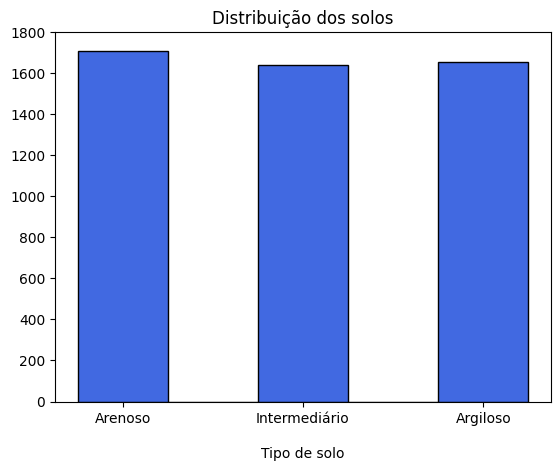

In [214]:
display(df_labels['soil_type'].value_counts())

plt.figure()
plt.title('Distribuição dos solos')
plt.hist(df_labels['soil_type'],bins=[0.75,1.25,1.75,2.25,2.75,3.25],edgecolor='black',color='royalblue')
plt.xticks([1,2,3],['Arenoso','Intermediário','Argiloso'])
plt.yticks(np.arange(0,1801,200))
plt.xlabel('\nTipo de solo')
plt.show()

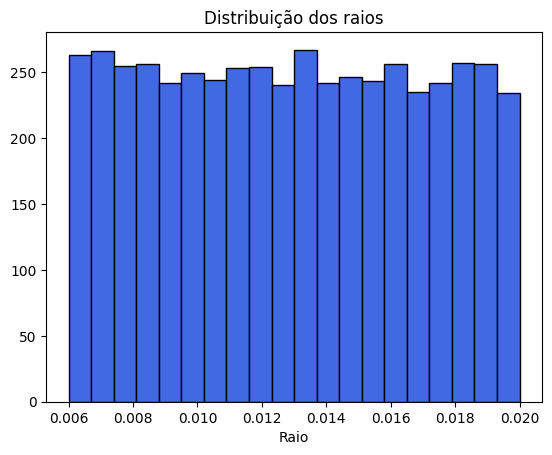

In [215]:
plt.figure()
plt.hist(df_labels['radius'],bins=20,edgecolor='black',color='royalblue')
plt.title('Distribuição dos raios')
plt.xlabel('Raio')
plt.show()

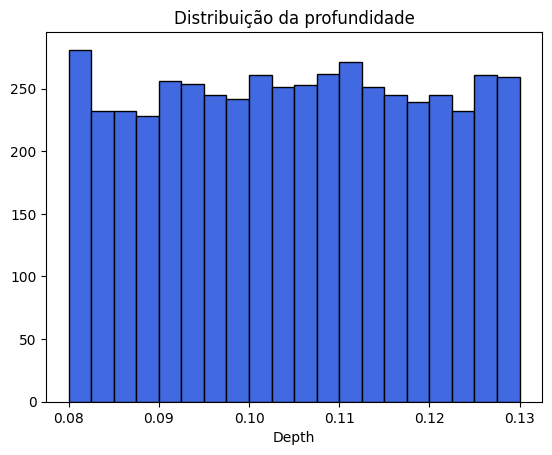

In [216]:
plt.figure()
plt.title('Distribuição da profundidade')
plt.hist(df_labels['pos_y'],bins=20,edgecolor='black',color='royalblue')
plt.xlabel('Depth')
plt.show()

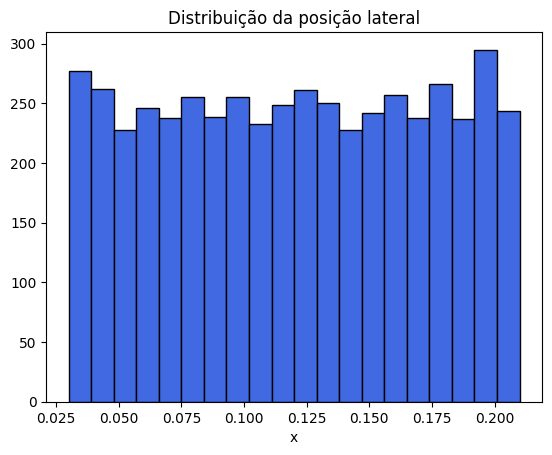

In [217]:
plt.figure()
plt.title('Distribuição da posição lateral')
plt.hist(df_labels['pos_x'],bins=20,edgecolor='black',color='royalblue')
plt.xlabel('x')
plt.show()

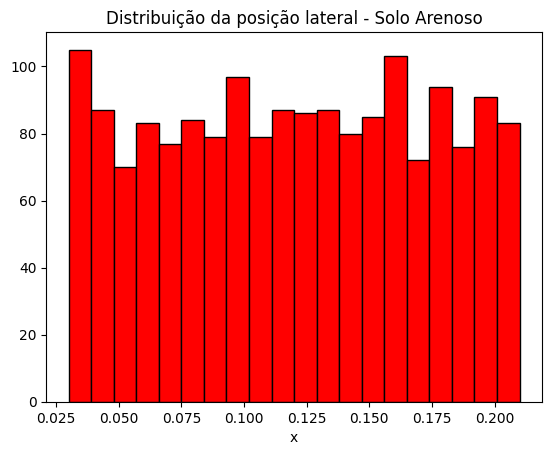

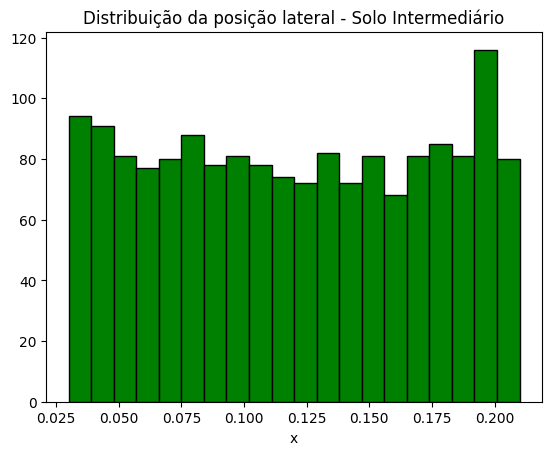

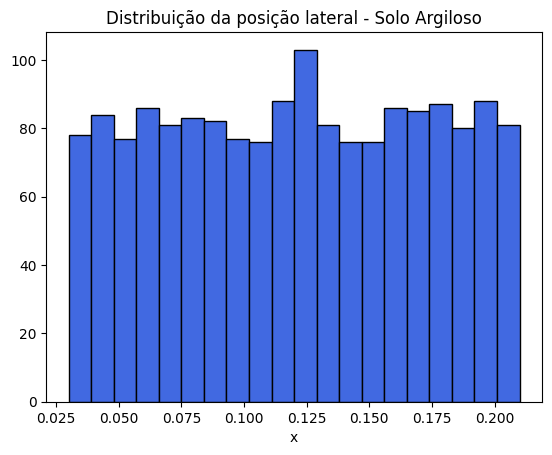

In [218]:
df_soil1 = df_labels[df_labels['soil_type']==1]
df_soil2 = df_labels[df_labels['soil_type']==2]
df_soil3 = df_labels[df_labels['soil_type']==3]

plt.figure()
plt.title('Distribuição da posição lateral - Solo Arenoso')
plt.hist(df_soil1['pos_x'],bins=20,edgecolor='black',color='red')
plt.xlabel('x')
plt.show()

plt.figure()
plt.title('Distribuição da posição lateral - Solo Intermediário')
plt.hist(df_soil2['pos_x'],bins=20,edgecolor='black',color='green')
plt.xlabel('x')
plt.show()

plt.figure()
plt.title('Distribuição da posição lateral - Solo Argiloso')
plt.hist(df_soil3['pos_x'],bins=20,edgecolor='black',color='royalblue')
plt.xlabel('x')
plt.show()

Primeiro teste

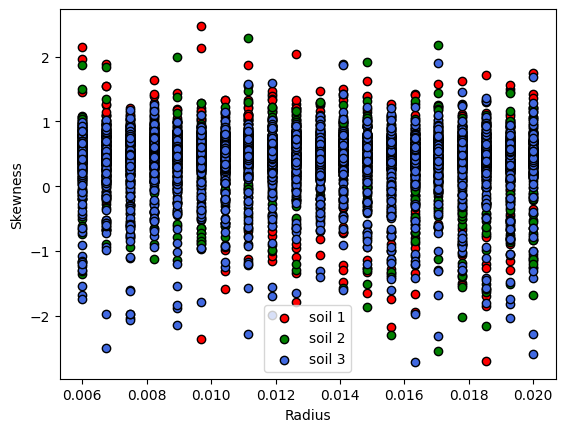

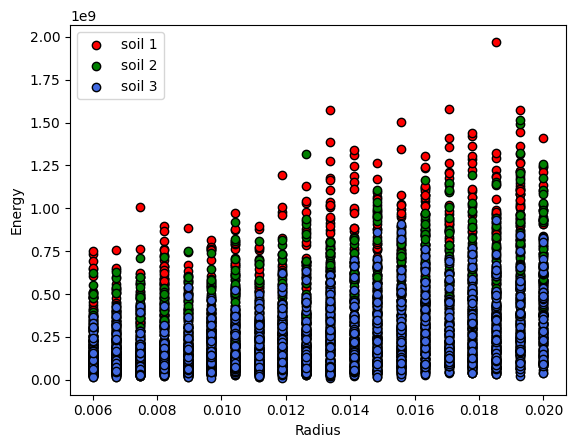

In [219]:
df = pd.read_csv('databasev3.csv')

x = df[['skewness','energy']]
y_rad = df['radius']

x1 = x[df['soil_type']==1]
x2 = x[df['soil_type']==2]
x3 = x[df['soil_type']==3]

y1 = y_rad[df['soil_type']==1]
y2 = y_rad[df['soil_type']==2]
y3 = y_rad[df['soil_type']==3]

plt.figure()
plt.ylabel('Skewness')
plt.xlabel('Radius')
plt.scatter(y1,x1['skewness'],color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2['skewness'],color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3['skewness'],color='royalblue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

plt.figure()
plt.ylabel('Energy')
plt.xlabel('Radius')
plt.scatter(y1,x1['energy'],color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2['energy'],color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3['energy'],color='royalblue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

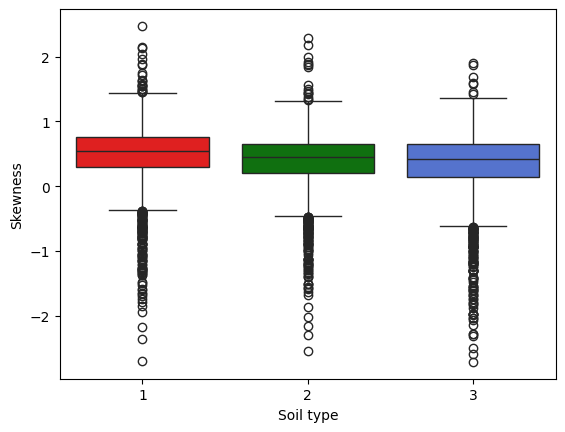

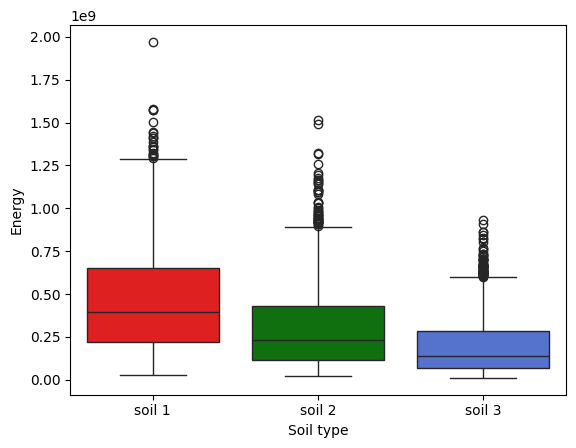

In [220]:
y_soil = df_labels['soil_type']

x1 = x1.rename(columns={'skewness':1,'energy':'soil 1'})
x2 = x2.rename(columns={'skewness':2,'energy':'soil 2'})
x3 = x3.rename(columns={'skewness':3,'energy':'soil 3'})

xs = pd.concat([x1[1].reset_index(drop=True),x2[2].reset_index(drop=True),x3[3].reset_index(drop=True)],axis=1)
xe = pd.concat([x1['soil 1'].reset_index(drop=True),x2['soil 2'].reset_index(drop=True),x3['soil 3'].reset_index(drop=True)],axis=1)

plt.figure()
plt.ylabel('Skewness')
plt.xlabel('Soil type')
sns.boxplot(xs,palette={1:'red',2:'green',3:'royalblue'})
plt.show()

plt.figure()
plt.ylabel('Energy')
plt.xlabel('Soil type')
sns.boxplot(xe,palette={'soil 1':'red','soil 2':'green','soil 3':'royalblue'})
plt.show()

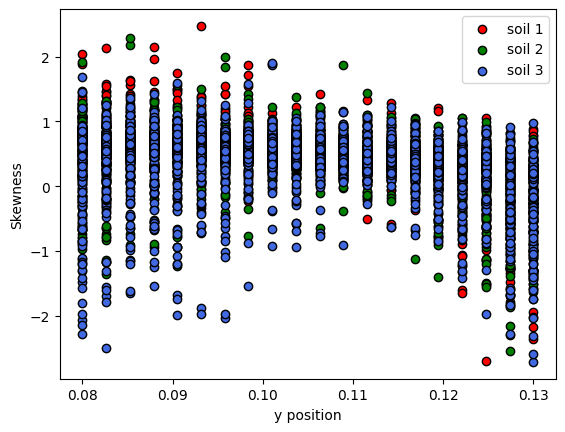

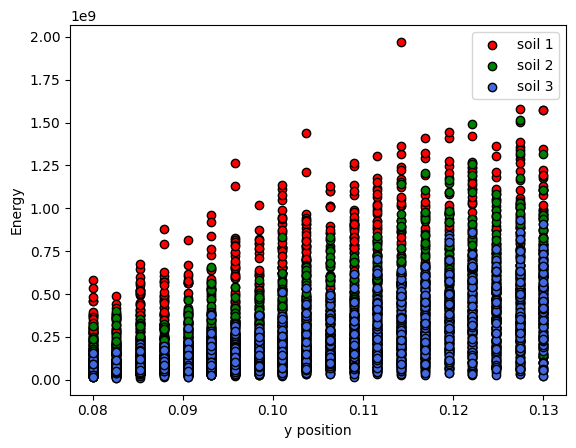

In [221]:
df = pd.read_csv('databasev3.csv')

x = df[['skewness','energy']]
y_rad = df['pos_y']

x1 = x[df['soil_type']==1]
x2 = x[df['soil_type']==2]
x3 = x[df['soil_type']==3]

y1 = y_rad[df['soil_type']==1]
y2 = y_rad[df['soil_type']==2]
y3 = y_rad[df['soil_type']==3]

plt.figure()
plt.ylabel('Skewness')
plt.xlabel('y position')
plt.scatter(y1,x1['skewness'],color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2['skewness'],color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3['skewness'],color='royalblue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

plt.figure()
plt.ylabel('Energy')
plt.xlabel('y position')
plt.scatter(y1,x1['energy'],color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2['energy'],color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3['energy'],color='royalblue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

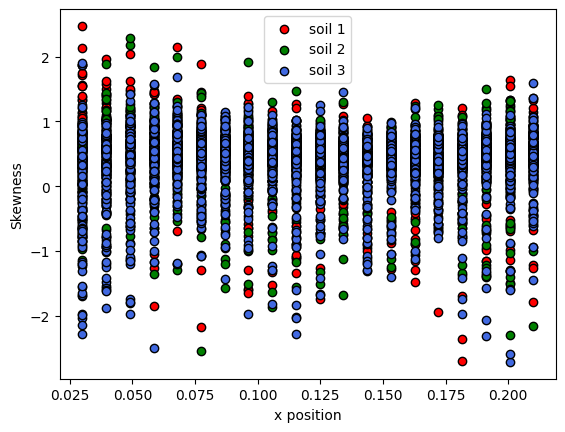

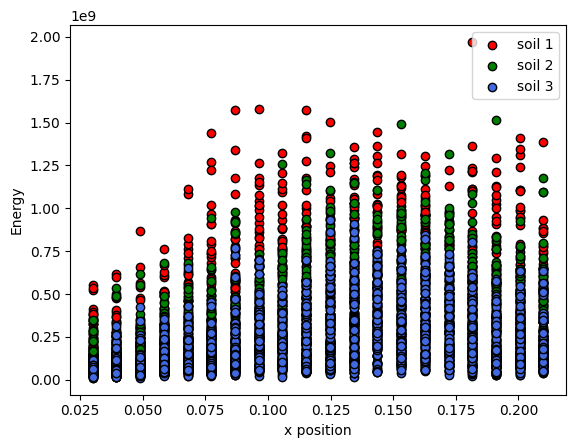

In [222]:
df = pd.read_csv('databasev3.csv')

x = df[['skewness','energy']]
y_rad = df['pos_x']

x1 = x[df['soil_type']==1]
x2 = x[df['soil_type']==2]
x3 = x[df['soil_type']==3]

y1 = y_rad[df['soil_type']==1]
y2 = y_rad[df['soil_type']==2]
y3 = y_rad[df['soil_type']==3]

plt.figure()
plt.ylabel('Skewness')
plt.xlabel('x position')
plt.scatter(y1,x1['skewness'],color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2['skewness'],color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3['skewness'],color='royalblue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

plt.figure()
plt.ylabel('Energy')
plt.xlabel('x position')
plt.scatter(y1,x1['energy'],color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2['energy'],color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3['energy'],color='royalblue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

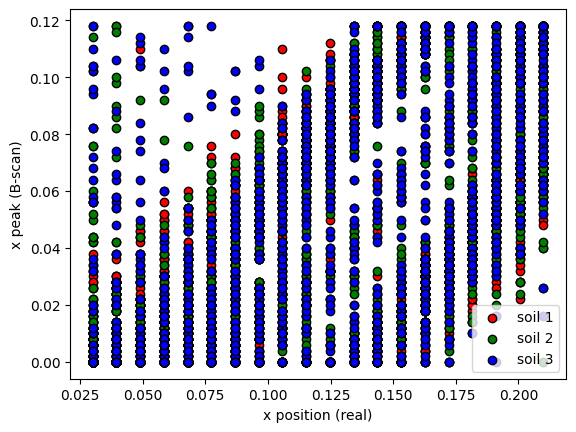

In [223]:
x = df_features['x_pico_env']
x1 = x[df_labels['soil_type'] == 1]
x2 = x[df_labels['soil_type'] == 2]
x3 = x[df_labels['soil_type'] == 3]

y1 = df_labels['pos_x'][df_labels['soil_type'] == 1]
y2 = df_labels['pos_x'][df_labels['soil_type'] == 2]
y3 = df_labels['pos_x'][df_labels['soil_type'] == 3]

plt.figure()
plt.xlabel('x position (real)')
plt.ylabel('x peak (B-scan)')
plt.scatter(y1,x1,color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2,color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3,color='blue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

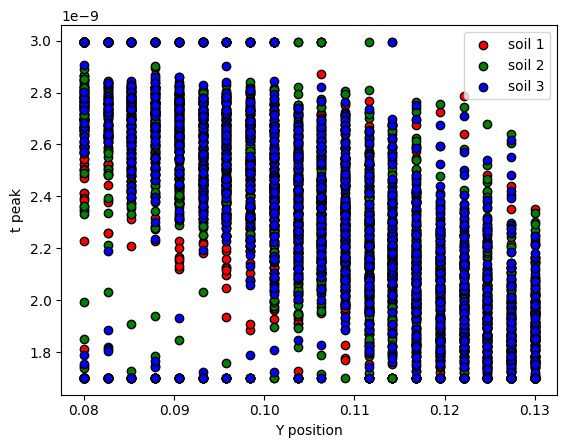

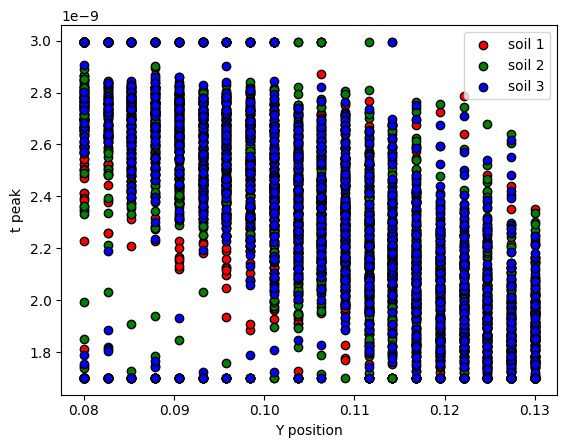

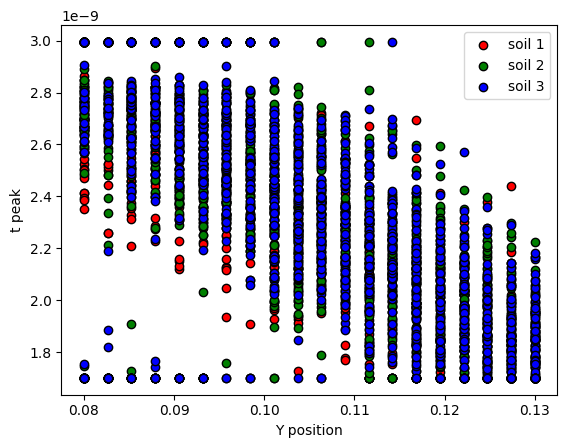

In [231]:
x = df_features['t_pico_env']
x1 = x[df_labels['soil_type'] == 1]
x2 = x[df_labels['soil_type'] == 2]
x3 = x[df_labels['soil_type'] == 3]

y1 = df_labels['pos_y'][df_labels['soil_type'] == 1]
y2 = df_labels['pos_y'][df_labels['soil_type'] == 2]
y3 = df_labels['pos_y'][df_labels['soil_type'] == 3]

plt.figure()
plt.xlabel('Y position')
plt.ylabel('t peak')
plt.scatter(y1,x1,color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2,color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3,color='blue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

x = df_features['t_pico_env'][df_features['t_pico_env']>0.1e-9]
x1 = x[df_labels['soil_type'] == 1]
x2 = x[df_labels['soil_type'] == 2]
x3 = x[df_labels['soil_type'] == 3]

y1 = df_labels['pos_y'][df_labels['soil_type'] == 1][df_features['t_pico_env']>0.1e-9]
y2 = df_labels['pos_y'][df_labels['soil_type'] == 2][df_features['t_pico_env']>0.1e-9]
y3 = df_labels['pos_y'][df_labels['soil_type'] == 3][df_features['t_pico_env']>0.1e-9]

plt.figure()
plt.xlabel('Y position')
plt.ylabel('t peak')
plt.scatter(y1,x1,color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2,color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3,color='blue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()

x = df_features['t_pico_env'][df_labels['pos_x']>0.08]
x1 = x[df_labels['soil_type'] == 1]
x2 = x[df_labels['soil_type'] == 2]
x3 = x[df_labels['soil_type'] == 3]

y1 = df_labels['pos_y'][df_labels['soil_type'] == 1][df_labels['pos_x']>0.08]
y2 = df_labels['pos_y'][df_labels['soil_type'] == 2][df_labels['pos_x']>0.08]
y3 = df_labels['pos_y'][df_labels['soil_type'] == 3][df_labels['pos_x']>0.08]

plt.figure()
plt.xlabel('Y position')
plt.ylabel('t peak')
plt.scatter(y1,x1,color='red',edgecolors='black',label='soil 1')
plt.scatter(y2,x2,color='green',edgecolors='black',label='soil 2')
plt.scatter(y3,x3,color='blue',edgecolors='black',label='soil 3')
plt.legend()
plt.show()